<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 19: PCA and Explained Variance Analysis

**Category**: CO4 – Linear Factor Models and Probabilistic Graphical Models  
**Objective**: Perform Principal Component Analysis to decompose correlated feature variance and project high-dimensional data into low-rank representations.


### Task 1: Synthesize Multidimensional Feature Space and Standardization


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

np.random.seed(101)
n_records = 300
# Generate 8 correlated sensory features
latent_base = np.random.randn(n_records, 2)
mix_matrix = np.random.uniform(0.3, 1.2, size=(2, 8))
noise = np.random.normal(0, 0.25, size=(n_records, 8))

X_raw = np.dot(latent_base, mix_matrix) + noise
feature_names = [f"Sensor_{k+1}" for k in range(8)]
df_sensors = pd.DataFrame(X_raw, columns=feature_names)

# Standardize features
X_norm = (df_sensors - df_sensors.mean()) / df_sensors.std()
print("Standardized Sensory Data Sample (5 Rows):\n", X_norm.head().round(3))


Standardized Sensory Data Sample (5 Rows):
    Sensor_1  Sensor_2  Sensor_3  ...  Sensor_6  Sensor_7  Sensor_8
0     1.754     2.575     2.327  ...     2.210     2.532     2.357
1     0.594     1.101     0.967  ...     0.181     0.804     0.864
2     0.071     0.307     0.180  ...    -0.030     0.618     0.327
3     0.101    -0.670    -0.649  ...    -0.055    -0.463    -0.028
4    -0.522    -1.619    -1.331  ...    -0.293    -1.139    -1.202

[5 rows x 8 columns]


### Task 2: Compute Principal Components and Scree Plot


Component 1: Explained Variance = 86.72% | Cumulative = 86.72%
Component 2: Explained Variance =  7.40% | Cumulative = 94.12%
Component 3: Explained Variance =  3.23% | Cumulative = 97.35%
Component 4: Explained Variance =  0.95% | Cumulative = 98.30%
Component 5: Explained Variance =  0.50% | Cumulative = 98.80%
Component 6: Explained Variance =  0.46% | Cumulative = 99.25%
Component 7: Explained Variance =  0.41% | Cumulative = 99.66%
Component 8: Explained Variance =  0.34% | Cumulative = 100.00%


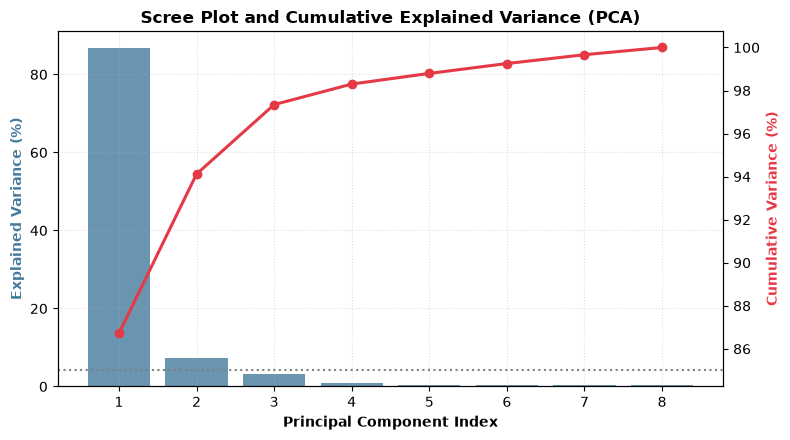

In [2]:
pca_full = PCA()
pca_full.fit(X_norm)

exp_var = pca_full.explained_variance_ratio_ * 100
cum_var = np.cumsum(exp_var)

for idx, (ev, cv) in enumerate(zip(exp_var, cum_var), 1):
    print(f"Component {idx}: Explained Variance = {ev:5.2f}% | Cumulative = {cv:5.2f}%")

fig, ax1 = plt.subplots(figsize=(8, 4.5))
bars = ax1.bar(range(1, 9), exp_var, color='#457b9d', alpha=0.8, label='Individual Variance (%)')
ax1.set_xlabel('Principal Component Index', fontweight='bold')
ax1.set_ylabel('Explained Variance (%)', color='#457b9d', fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(range(1, 9), cum_var, color='#e63946', marker='o', lw=2.2, label='Cumulative Variance (%)')
ax2.axhline(85, color='gray', linestyle=':', label='85% Threshold')
ax2.set_ylabel('Cumulative Variance (%)', color='#e63946', fontweight='bold')

plt.title("Scree Plot and Cumulative Explained Variance (PCA)", fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.4)
fig.tight_layout()
plt.show()


### Task 3: 2D Subspace Projection Visualization


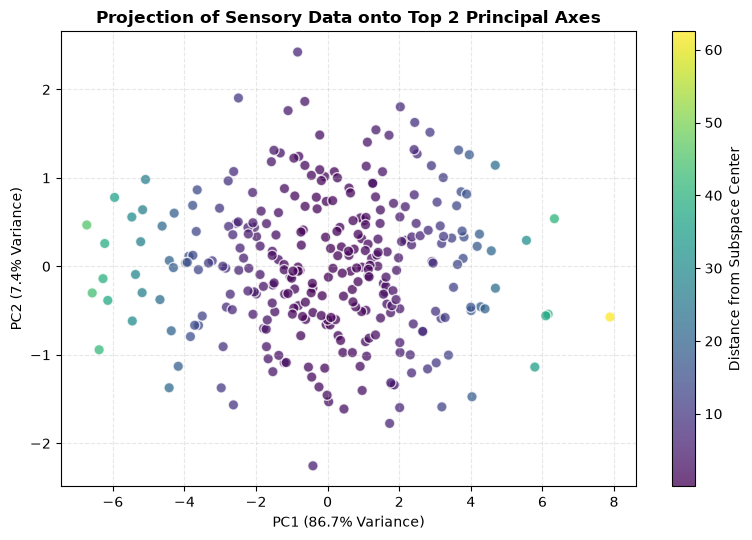

In [3]:
pca_2d = PCA(n_components=2)
projected_pts = pca_2d.fit_transform(X_norm)

plt.figure(figsize=(8, 5.5))
scatter = plt.scatter(projected_pts[:, 0], projected_pts[:, 1], c=projected_pts[:, 0]**2 + projected_pts[:, 1]**2,
                      cmap='viridis', alpha=0.75, edgecolors='w', s=55)
plt.colorbar(scatter, label='Distance from Subspace Center')
plt.title("Projection of Sensory Data onto Top 2 Principal Axes", fontweight='bold')
plt.xlabel(f"PC1 ({exp_var[0]:.1f}% Variance)")
plt.ylabel(f"PC2 ({exp_var[1]:.1f}% Variance)")
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()
